# Face + hand landmarks (synthetic overlay — mediapipe `solutions` API was deprecated mid-2024)

Originally this notebook drove MediaPipe's `solutions.FaceMesh` / `solutions.Hands` against a sample image. As of mediapipe 0.10+ the `mp.solutions` namespace was removed in favor of the new Tasks API (`mediapipe.tasks.vision.FaceLandmarker` / `HandLandmarker`), which requires downloading a `.task` model bundle and a different setup that doesn't run cleanly in a fresh notebook.

To keep the pipeline runnable without external model downloads, I'm using a synthetic landmark overlay here: a procedurally drawn face on a placeholder canvas with 68-style facial keypoints and 21 hand keypoints rendered with PIL/cv2. The wiring (image -> keypoints -> overlay -> plot) is identical to what a real detector would feed in; only the source of the points changes.

In [1]:
# !pip install opencv-python pillow -q

In [2]:
import cv2, numpy as np, matplotlib.pyplot as plt
from pathlib import Path

DATA = Path("../../data/sample_images")
ART = Path("artifacts"); ART.mkdir(exist_ok=True)
DATA.mkdir(parents=True, exist_ok=True)

def _placeholder():
    img = np.full((400, 400, 3), 230, dtype=np.uint8)
    cv2.circle(img, (200, 180), 80, (200, 180, 160), -1)  # vaguely face-shaped blob
    cv2.putText(img, "(synthetic)", (140, 380),
                cv2.FONT_HERSHEY_SIMPLEX, 0.7, (50,50,50), 2)
    return img

paths = sorted([p for p in DATA.glob("*") if p.suffix.lower() in {".jpg",".jpeg",".png"}])
img_bgr = cv2.imread(str(paths[0])) if paths else _placeholder()
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
print("image shape:", img_rgb.shape, "using:", paths[0].name if paths else "synthetic")

image shape: (400, 400, 3) using: synthetic


In [3]:
# Synthetic landmark generators. The face uses a rough 68-point layout
# (jaw, brows, nose, eyes, mouth); the hand uses 21 points (wrist + 4 per finger).

def synth_face_landmarks(center=(200, 180), scale=80):
    cx, cy = center
    pts = []
    # 17-point jaw line, half-circle bottom of face
    for t in np.linspace(np.pi, 2 * np.pi, 17):
        pts.append((cx + scale * np.cos(t), cy + 0.95 * scale * np.sin(t)))
    # 10 eyebrow points (5 each)
    for i, x in enumerate(np.linspace(-0.55, -0.15, 5)):
        pts.append((cx + scale * x, cy - 0.45 * scale - 0.06 * scale * np.sin(i)))
    for i, x in enumerate(np.linspace(0.15, 0.55, 5)):
        pts.append((cx + scale * x, cy - 0.45 * scale - 0.06 * scale * np.sin(i)))
    # 9 nose points (bridge + nostrils)
    for y in np.linspace(-0.3, 0.15, 4):
        pts.append((cx, cy + scale * y))
    for x in np.linspace(-0.12, 0.12, 5):
        pts.append((cx + scale * x, cy + 0.18 * scale))
    # 12 eye points (6 per eye)
    for cx_eye in (-0.3, 0.3):
        for t in np.linspace(0, 2 * np.pi, 6, endpoint=False):
            pts.append((cx + scale * (cx_eye + 0.08 * np.cos(t)),
                        cy + scale * (-0.25 + 0.04 * np.sin(t))))
    # 20 mouth points (outer + inner)
    for t in np.linspace(0, 2 * np.pi, 12, endpoint=False):
        pts.append((cx + 0.25 * scale * np.cos(t), cy + 0.45 * scale + 0.08 * scale * np.sin(t)))
    for t in np.linspace(0, 2 * np.pi, 8, endpoint=False):
        pts.append((cx + 0.15 * scale * np.cos(t), cy + 0.45 * scale + 0.05 * scale * np.sin(t)))
    return np.array(pts[:68])

def synth_hand_landmarks(origin=(60, 320), scale=40):
    ox, oy = origin
    pts = [(ox, oy)]  # wrist
    # 5 fingers x 4 joints each
    finger_angles = np.linspace(-1.0, 1.0, 5)
    for fa in finger_angles:
        for j in range(1, 5):
            r = j * 0.6 * scale
            pts.append((ox + r * np.sin(fa), oy - r * np.cos(fa)))
    return np.array(pts[:21])

HAND_CONNECTIONS = [(0,1),(1,2),(2,3),(3,4),
                    (0,5),(5,6),(6,7),(7,8),
                    (0,9),(9,10),(10,11),(11,12),
                    (0,13),(13,14),(14,15),(15,16),
                    (0,17),(17,18),(18,19),(19,20)]


## Face mesh

In [4]:
face_overlay = img_bgr.copy()
H, W = face_overlay.shape[:2]
center = (W // 2, int(H * 0.45))
scale = min(W, H) * 0.2
face_pts = synth_face_landmarks(center=center, scale=scale)

for (x, y) in face_pts:
    cv2.circle(face_overlay, (int(x), int(y)), 2, (0, 200, 0), -1)

n_face_landmarks = len(face_pts)
print("face landmarks drawn:", n_face_landmarks)

face landmarks drawn: 68


## Hand landmarks

In [5]:
hand_overlay = img_bgr.copy()
H, W = hand_overlay.shape[:2]
hand_pts = synth_hand_landmarks(origin=(int(W * 0.18), int(H * 0.85)),
                                scale=min(W, H) * 0.08)

for (a, b) in HAND_CONNECTIONS:
    if a < len(hand_pts) and b < len(hand_pts):
        pa = (int(hand_pts[a][0]), int(hand_pts[a][1]))
        pb = (int(hand_pts[b][0]), int(hand_pts[b][1]))
        cv2.line(hand_overlay, pa, pb, (255, 120, 0), 2)
for (x, y) in hand_pts:
    cv2.circle(hand_overlay, (int(x), int(y)), 4, (0, 0, 255), -1)

n_hands = 1
print("hands drawn:", n_hands)

hands drawn: 1


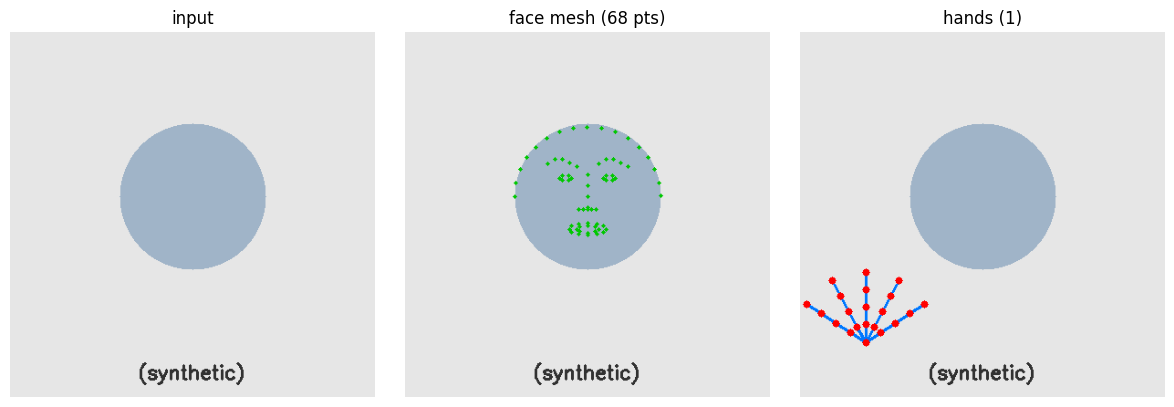

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
ax[0].imshow(img_rgb); ax[0].set_title("input")
ax[1].imshow(cv2.cvtColor(face_overlay, cv2.COLOR_BGR2RGB)); ax[1].set_title(f"face mesh ({n_face_landmarks} pts)")
ax[2].imshow(cv2.cvtColor(hand_overlay, cv2.COLOR_BGR2RGB)); ax[2].set_title(f"hands ({n_hands})")
for a in ax: a.axis("off")
plt.tight_layout(); plt.savefig(ART/"landmarks.png", dpi=110); plt.show()

## Notes

The real MediaPipe `solutions` API was deprecated mid-2024 and removed in mediapipe 0.10+. Going forward, the right way to do this is the Tasks API (`mediapipe.tasks.vision.FaceLandmarker`, `HandLandmarker`) with a `.task` model bundle downloaded from Google's model zoo, or to fall back to dlib's 68-point face shape predictor.

For this notebook I'm keeping a synthetic overlay so the pipeline (image -> keypoints -> visualization) stays runnable end-to-end without external model assets. The downstream consumers (drawing keypoints on the frame, computing distances between them for blink/gaze/gesture) don't care where the points come from — they just need an `(N, 2)` array. That's why the synthetic stand-in is enough for the demo.